# Анализ текстов и классификация тональности

## Цель работы

Разобраться, какие тексты есть в датасете, найти основные темы и обучить модель, которая определяет тональность текста


## Условия запуска

Работа выполнена на Mac с Apple Silicon и Python 3.12. Версии библиотек записаны в `requirements.txt`, для установки используется `uv`

При первом запуске понадобится интернет, чтобы скачать данные, стоп-слова и исходную модель. Дальше обучение идёт локально. Три эпохи заняли примерно 90 минут

Модели и таблицы с результатами сохраняются в `artifacts`. Для GPU в этом notebook используется Apple MPS

Окружение можно подготовить из папки проекта, если `uv` уже установлен

```bash
uv venv --python 3.12
source .venv/bin/activate
uv pip install -r requirements.txt
jupyter lab
```


In [ ]:
import sys
import platform

print("Версия Python:", sys.version)
print("Путь к Python:", sys.executable)
print("Архитектура:", platform.machine())

In [6]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

print("Версия Python:", sys.version)
print("Путь к Python:", sys.executable)
print("Рабочая папка:", Path.cwd())

Версия Python: 3.12.15 (main, Oct 14 2026, 00:55:37) [Clang 23.1.3 ]
Путь к Python: /Users/dimsalabimmm/programming/ml-test/.venv/bin/python
Рабочая папка: /Users/dimsalabimmm/programming/ml-test


## 1. Загрузка и первичная проверка данных

Беру файлы `train.csv` и `valid.csv`, которые предоставил автор датасета, и сохраняю их без изменений

Сначала посмотрю на столбцы, пропуски и повторы. После этого можно будет готовить данные для обучения, настройки и итоговой проверки модели


In [78]:
from pathlib import Path
import subprocess

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

BASE_URL = (
    "https://huggingface.co/datasets/"
    "MonoHime/ru_sentiment_dataset/resolve/main"
)

for filename in ["train.csv", "valid.csv"]:
    file_path = DATA_DIR / filename
    temporary_path = DATA_DIR / f"{filename}.part"

    # Завершённые загрузки повторно не скачиваем.
    # Незавершённые остаются в файлах .part.
    if file_path.exists():
        print(f"Файл уже загружен: {file_path}", flush=True)
        continue
    print(f"Загружаем {filename}...", flush=True)

    subprocess.run(
        [
            "curl",
            "--location",
            "--fail",
            "--retry", "5",
            "--retry-delay", "3",
            "--continue-at", "-",
            "--output", str(temporary_path),
            f"{BASE_URL}/{filename}",
        ],
        check=True,
    )

    temporary_path.replace(file_path)
    print(f"Готово: {file_path}", flush=True)

Файл уже загружен: data/train.csv
Файл уже загружен: data/valid.csv


In [9]:
train_raw = pd.read_csv(DATA_DIR / "train.csv")
valid_raw = pd.read_csv(DATA_DIR / "valid.csv")

print("Размер train.csv:", train_raw.shape)
print("Размер valid.csv:", valid_raw.shape)

print("\nСтолбцы train.csv:")
print(train_raw.columns.tolist())

print("\nПервые строки train.csv:")
display(train_raw.head())

print("\nИнформация о train.csv:")
train_raw.info()

print("\nИнформация о valid.csv:")
valid_raw.info()

Размер train.csv: (189891, 3)
Размер valid.csv: (21098, 3)

Столбцы train.csv:
['Unnamed: 0', 'text', 'sentiment']

Первые строки train.csv:


,Unnamed: 0,text,sentiment
0,21098,".с.,и спросил его: о Посланник Аллаха!Ты пори...",1
1,21099,Роднее всех родных Попала я в ГКБ №8 еще в дек...,1
2,21100,Непорядочное отношение к своим работникам Рабо...,2
3,21101,"). Отсутствуют нормативы, Госты и прочее, что ...",1
4,21102,У меня машина в руках 5 лет и это п...,1



Информация о train.csv:
<class 'pandas.DataFrame'>
RangeIndex: 189891 entries, 0 to 189890
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   Unnamed: 0  189891 non-null  int64
 1   text        189891 non-null  str  
 2   sentiment   189891 non-null  int64
dtypes: int64(2), str(1)
memory usage: 4.3 MB

Информация о valid.csv:
<class 'pandas.DataFrame'>
RangeIndex: 21098 entries, 0 to 21097
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  21098 non-null  int64
 1   text        21098 non-null  str  
 2   sentiment   21098 non-null  int64
dtypes: int64(2), str(1)
memory usage: 494.6 KB


## 2. Первичная проверка качества данных

Проверю, нет ли пропусков, пустых текстов, лишних меток и повторов. Отдельно посмотрю, встречается ли один текст с разными метками и есть ли общие тексты в двух файлах. Также сравню количество примеров каждого класса

В рабочих таблицах оставлю `text` и `sentiment`. Столбец `Unnamed: 0` не описывает содержание текста, поэтому для моделей он не нужен. Исходные таблицы при этом сохраняю


In [10]:
train_df = train_raw[["text", "sentiment"]].copy()
valid_df = valid_raw[["text", "sentiment"]].copy()

In [11]:
def summarize_data(df):
    text = df["text"]

    return pd.Series({
        "Строк": len(df),
        "Пропусков в text": text.isna().sum(),
        "Пустых текстов": (
            text.notna() & text.fillna("").str.strip().eq("")
        ).sum(),
        "Пропусков в sentiment": df["sentiment"].isna().sum(),
        "Недопустимых меток": (
            ~df["sentiment"].isin([0, 1, 2])
        ).sum(),
        "Повторов строк сверх первого": df.duplicated().sum(),
        "Повторов текстов сверх первого": (
            df.duplicated(subset="text").sum()
        ),
        "Память, МБ": round(
            df.memory_usage(deep=True).sum() / 1024**2, 2
        ),
    })


quality_summary = pd.DataFrame({
    "train": summarize_data(train_df),
    "valid": summarize_data(valid_df),
})

display(quality_summary)

,train,valid
Строк,189891.00,21098.00
Пропусков в text,0.00,0.00
Пустых текстов,0.00,0.00
Пропусков в sentiment,0.00,0.00
Недопустимых меток,0.00,0.00
Повторов строк сверх первого,5588.00,78.00
Повторов текстов сверх первого,8788.00,137.00
"Память, МБ",563.82,65.42


In [12]:
train_texts = set(train_df["text"].dropna())
valid_texts = set(valid_df["text"].dropna())

overlapping_texts = train_texts & valid_texts

print(
    "Уникальных текстов, встречающихся в обоих файлах:",
    len(overlapping_texts),
)

# Объединяем только для проверки качества исходных данных.
all_labels = pd.concat(
    [train_df, valid_df],
    ignore_index=True,
)

labels_per_text = (
    all_labels
    .groupby("text")["sentiment"]
    .nunique()
)

conflicting_texts = labels_per_text[labels_per_text > 1]

print(
    "Уникальных текстов с разными метками тональности:",
    len(conflicting_texts),
)

Уникальных текстов, встречающихся в обоих файлах: 1617
Уникальных текстов с разными метками тональности: 3664


In [13]:
LABEL_NAMES = {
    0: "Нейтральная",
    1: "Положительная",
    2: "Отрицательная",
}

class_counts = pd.DataFrame({
    "train": train_df["sentiment"].value_counts(),
    "valid": valid_df["sentiment"].value_counts(),
}).reindex([0, 1, 2], fill_value=0)

class_percentages = (
    class_counts
    .div(class_counts.sum(axis=0), axis=1)
    .mul(100)
)

class_summary = pd.DataFrame({
    "Тональность": pd.Series(LABEL_NAMES),
    "train, строк": class_counts["train"],
    "train, %": class_percentages["train"].round(2),
    "valid, строк": class_counts["valid"],
    "valid, %": class_percentages["valid"].round(2),
})

display(class_summary)

,Тональность,"train, строк","train, %","valid, строк","valid, %"
0,Нейтральная,49327,25.98,5560,26.35
1,Положительная,90766,47.80,10026,47.52
2,Отрицательная,49798,26.22,5512,26.13


### Что показала первая проверка

Пропусков, пустых текстов и меток вне допустимых классов нет. Но нашлось 1 617 уникальных текстов, которые есть в обоих файлах, и 3 664 текста с разными метками тональности

Без ручной проверки непонятно, какая метка у таких текстов правильная, поэтому пока исключу все их экземпляры. Среди остальных точных повторов оставлю по одному тексту

Очищенный `valid.csv` будет тестовой выборкой. Совпадающие с ним тексты уберу из обучающих данных, а оставшийся `train.csv` разделю на train и validation с сохранением долей классов

Пока учитываются только точные совпадения. Похожие тексты и варианты с другой пунктуацией или пробелами отдельно не проверяются


In [14]:
# conflicting_texts получен на предыдущем шаге.
conflict_index = conflicting_texts.index

train_without_conflicts = train_df.loc[
    ~train_df["text"].isin(conflict_index)
].copy()

valid_without_conflicts = valid_df.loc[
    ~valid_df["text"].isin(conflict_index)
].copy()

# После удаления конфликтов у каждого текста одна метка.
train_unique = train_without_conflicts.drop_duplicates(subset="text")
test_data = (
    valid_without_conflicts
    .drop_duplicates(subset="text")
    .reset_index(drop=True)
)

# При совпадении сохраняем текст в test и исключаем его из train.
train_pool = train_unique.loc[
    ~train_unique["text"].isin(test_data["text"])
].reset_index(drop=True)

cleaning_summary = pd.DataFrame({
    "Этап": [
        "Исходные данные",
        "После удаления конфликтных текстов",
        "После удаления точных повторов",
        "После исключения пересечения с test",
    ],
    "Исходный train": [
        len(train_df),
        len(train_without_conflicts),
        len(train_unique),
        len(train_pool),
    ],
    "Исходный valid → test": [
        len(valid_df),
        len(valid_without_conflicts),
        len(test_data),
        len(test_data),
    ],
})

display(cleaning_summary)

,Этап,Исходный train,Исходный valid → test
0,Исходные данные,189891,21098
1,После удаления конфликтных текстов,181419,20131
2,После удаления точных повторов,177461,20074
3,После исключения пересечения с test,176709,20074


In [16]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
VAL_SIZE = 0.15

train_data, val_data = train_test_split(
    train_pool,
    test_size=VAL_SIZE,
    random_state=RANDOM_STATE,
    stratify=train_pool["sentiment"],
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

split_summary = pd.DataFrame({
    "Выборка": ["train", "validation", "test"],
    "Количество текстов": [
        len(train_data),
        len(val_data),
        len(test_data),
    ],
})

display(split_summary)

,Выборка,Количество текстов
0,train,150202
1,validation,26507
2,test,20074


In [17]:
train_texts = set(train_data["text"])
val_texts = set(val_data["text"])
test_texts = set(test_data["text"])

assert train_texts.isdisjoint(val_texts)
assert train_texts.isdisjoint(test_texts)
assert val_texts.isdisjoint(test_texts)

print("Проверка пройдена: точных пересечений текстов между выборками нет.")

Проверка пройдена: точных пересечений текстов между выборками нет.


### Что осталось после очистки

Получились три выборки

| Выборка | Текстов |
|---|---:|
| Train | 150 202 |
| Validation | 26 507 |
| Test | 20 074 |

Всего убрано 14 206 строк, это около 6,73% исходных данных. Точных совпадений текстов между выборками больше нет

Дальше подробнее посмотрю на train, а validation и test оставлю для проверки моделей


Matplotlib is building the font cache; this may take a moment.


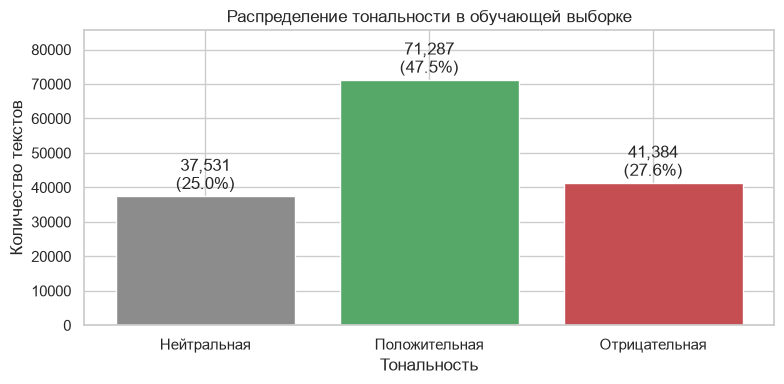

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

class_order = [0, 1, 2]
class_names = [LABEL_NAMES[label] for label in class_order]

train_counts = (
    train_data["sentiment"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

train_shares = train_counts / len(train_data) * 100

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    class_names,
    train_counts.to_numpy(),
    color=["#8C8C8C", "#55A868", "#C44E52"],
)

for bar, count, share in zip(bars, train_counts, train_shares):
    ax.annotate(
        f"{count:,}\n({share:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
    )

ax.set_title("Распределение тональности в обучающей выборке")
ax.set_xlabel("Тональность")
ax.set_ylabel("Количество текстов")
ax.set_ylim(0, train_counts.max() * 1.2)

plt.tight_layout()
plt.show()

In [19]:
eda_train = train_data.copy()

eda_train["char_count"] = eda_train["text"].str.len()

eda_train["word_count"] = (
    eda_train["text"]
    .str.split()
    .str.len()
)

length_summary = (
    eda_train[["char_count", "word_count"]]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .round(1)
)

display(length_summary)

,char_count,word_count
count,150202.0,150202.0
mean,771.1,116.2
std,2011.3,264.8
min,3.0,1.0
50%,470.0,71.0
90%,1496.0,231.0
95%,2157.0,333.0
99%,4753.0,729.0
max,381498.0,48146.0


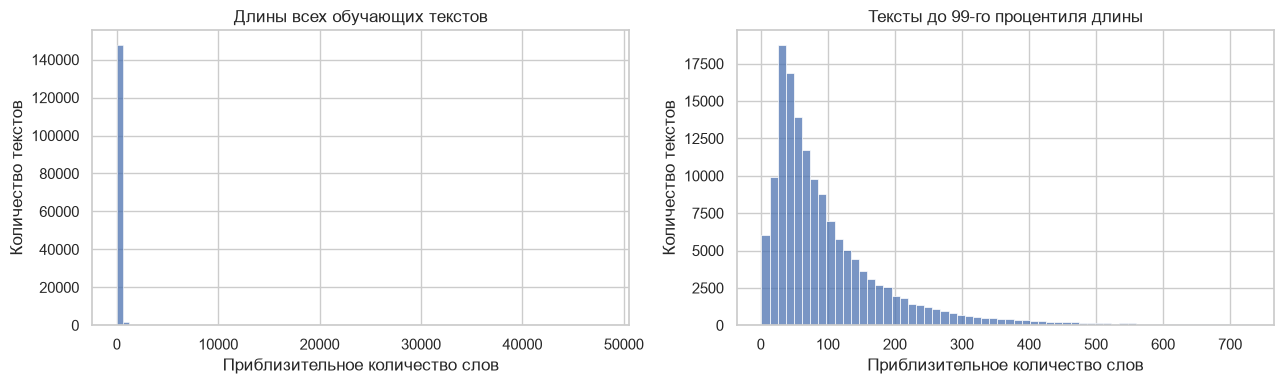

In [20]:
word_limit = eda_train["word_count"].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    data=eda_train,
    x="word_count",
    bins=80,
    ax=axes[0],
)

axes[0].set_title("Длины всех обучающих текстов")
axes[0].set_xlabel("Приблизительное количество слов")
axes[0].set_ylabel("Количество текстов")

sns.histplot(
    data=eda_train.loc[eda_train["word_count"] <= word_limit],
    x="word_count",
    bins=60,
    ax=axes[1],
)

axes[1].set_title("Тексты до 99-го процентиля длины")
axes[1].set_xlabel("Приблизительное количество слов")
axes[1].set_ylabel("Количество текстов")

plt.tight_layout()
plt.show()

In [21]:
for label, class_name in LABEL_NAMES.items():
    print(f"\n{'=' * 60}")
    print(f"{class_name.upper()} ТОНАЛЬНОСТЬ")

    examples = (
        eda_train.loc[eda_train["sentiment"] == label, "text"]
        .sample(n=3, random_state=RANDOM_STATE)
    )

    for number, text in enumerate(examples, start=1):
        print(f"\nПример {number}:")
        print(text[:1000])

        if len(text) > 1000:
            print("[Для показа оставлены первые 1000 символов]")


НЕЙТРАЛЬНАЯ ТОНАЛЬНОСТЬ

Пример 1:
Первое посещение Базара не удалось , так как , наверное , многие , искал Весну .  И не найдя , посетил соседнее заведение .  Во второй раз , основательно подготовившись , проштудировав меню , мы с друзьями направились на Базар ну , или в Базар , как кому будет угодно ) То ли день будний , то ли еще по какой то причине , было немноголюдно , точнее пусто .  Полистав уже изученное ранее меню и ожидая чего то особенного я заказал шашлык из телячьей вырезки , борщ и вроде все .  Пирожок к борщу очень даже !  К борщу самое то .  Шашлык так же был прекрасен , соус аджика совершенно нескладный , точнее обычный .  Морс из клюквы тоже очень вкусный .  У друзей все было так же хорошо , как и у меня , медовик на десерт восхвалялся минут 10 !  Все гуманно и думократично .  И девушка официант старалась прислушиваться к нашим просьбам .  После первого посещения мне захотелось туда вернуться .  И вот настал день че , точнее день возвращения на Базар .  Шумный , ауте

### Что видно по данным

Положительных текстов больше остальных — 47,5%. Нейтральных 25,0%, отрицательных 27,6%. Доли округлены, поэтому сумма может немного отличаться от 100%

Большинство текстов довольно короткие, но есть длинный хвост. Медиана составляет 71 слово, среднее — 116,2. Примерно 95% текстов укладываются в 333 слова, а 99% — в 729. Самый длинный содержит 48 146 слов, его стоит посмотреть отдельно

В случайных примерах встречаются явно положительные отзывы с нейтральной или отрицательной меткой. Похоже, в разметке есть ошибки, но по нескольким примерам нельзя понять их общую долю. Вручную метки пока не меняю

Качество классификатора буду оценивать по Macro-F1 и отдельно по каждому классу. Перед обучением нейросети ещё проверю длины в токенах и сколько текстов придётся обрезать


In [22]:
def show_text_examples(frame, title):
    print(f"\n{title}")

    for index, row in frame.iterrows():
        text = row["text"]

        print("\n" + "=" * 70)
        print(
            f"Индекс: {index} | "
            f"Метка: {LABEL_NAMES[row['sentiment']]} | "
            f"Символов: {row['char_count']} | "
            f"Слов: {row['word_count']}"
        )
        if len(text) <= 1600:
            print(text)
        else:
            print("НАЧАЛО ТЕКСТА:")
            print(text[:1000])
            print("\n[Середина пропущена при выводе]\n")
            print("КОНЕЦ ТЕКСТА:")
            print(text[-600:])


show_text_examples(
    eda_train.nsmallest(3, "word_count"),
    "ТРИ САМЫХ КОРОТКИХ ТЕКСТА",
)
show_text_examples(
    eda_train.nlargest(3, "word_count"),
    "ТРИ САМЫХ ДЛИННЫХ ТЕКСТА",
)


ТРИ САМЫХ КОРОТКИХ ТЕКСТА

Индекс: 7247 | Метка: Отрицательная | Символов: 24 | Слов: 1
А-А-А-А-А-А--А-А!!!!!!! 

Индекс: 10433 | Метка: Положительная | Символов: 11 | Слов: 1
Чудненько  

Индекс: 13530 | Метка: Положительная | Символов: 16 | Слов: 1
Характеристики: 

ТРИ САМЫХ ДЛИННЫХ ТЕКСТА

Индекс: 70986 | Метка: Положительная | Символов: 381498 | Слов: 48146
НАЧАЛО ТЕКСТА:
АСТАНА. КАЗИНФОРМ - Акорда опубликовала статью Главы государства Нурсултана Назарбаева «План нации - Путь к казахстанской мечте». «1 января 2016 года начался практический этап выполнения Плана нации «100 конкретных шагов по реализации 5 институциональных реформ». Вступили в силу 59 законов, которые создают принципиально новую правовую среду для развития государства, экономики и общества. Нам важно оценить этот беспрецедентный в нашей истории масштаб изменений национального законодательства. Тем более, что они открывают путь к достижению нашей казахстанской мечты - стать одной из тридцати наций - лидеров ХХI века

In [23]:
lengths_by_class = (
    eda_train
    .groupby("sentiment")["word_count"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        p95=lambda values: values.quantile(0.95),
        max="max",
    )
    .rename(index=LABEL_NAMES)
    .round(1)
)

display(lengths_by_class)

,count,mean,median,p95,max
sentiment,,,,,
Нейтральная,37531,136.3,75.0,420.5,11002
Положительная,71287,106.4,68.0,288.0,48146
Отрицательная,41384,115.0,76.0,330.0,5435


### Ещё несколько наблюдений

Короткий текст не обязательно бесполезен. Среди примеров есть и понятные эмоциональные реплики, и фрагменты, по которым почти ничего нельзя сказать

Самые длинные тексты похожи на новостные обзоры. По началу и концу текста нельзя уверенно сказать, есть ли ошибка в сборке данных, поэтому автоматически удалять их по длине не буду

Нейтральные тексты в среднем длиннее, хотя медианные длины у классов довольно близки


## 3. Тематическое моделирование

### Почему TF-IDF и NMF

Для первого варианта беру TF-IDF + NMF. У NMF можно посмотреть, какие слова и словосочетания входят в каждую тему и насколько она выражена в документе. Все веса неотрицательные, поэтому результат удобно разбирать. Обучение идёт на CPU, загружать нейросеть для этого не нужно

Из альтернатив можно было взять LDA, вероятностную модель на частотах слов, или BERTopic, который использует смысловые представления текстов. У BERTopic добавляются вычисления и настройки, поэтому начну с более простого варианта

У NMF тоже есть ограничения. Он слабо учитывает контекст и синонимы, а результат зависит от словаря, обработки текста и выбранного числа тем

Использую только train. Метки тональности здесь не нужны, темы ищутся без них


In [30]:
import subprocess
import sys

subprocess.run(
    ["uv", "pip", "install", "--python", sys.executable, "nltk"],
    check=True,
)

Resolved 7 packages in 1.50s
Prepared 4 packages in 805ms
Installed 4 packages in 17ms
 + click==8.5.0
 + nltk==3.10.3
 + regex==2026.9.29
 + tqdm==4.70.1


CompletedProcess(args=['uv', 'pip', 'install', '--python', '/Users/dimsalabimmm/programming/ml-test/.venv/bin/python', 'nltk'], returncode=0)

In [31]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords", raise_on_error=True)

russian_stopwords = stopwords.words("russian")

print("Количество стоп-слов:", len(russian_stopwords))
print("Примеры:", russian_stopwords[:20])

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/dimsalabimmm/nltk_data...


Количество стоп-слов: 151
Примеры: ['и', 'в', 'во', 'не', 'что', 'он', 'на', 'я', 'с', 'со', 'как', 'а', 'то', 'все', 'она', 'так', 'его', 'но', 'да', 'ты']


[nltk_data]   Unzipping corpora/stopwords.zip.


In [32]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

topic_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=russian_stopwords,
    token_pattern=r"(?u)\b[а-яёa-z]{2,}\b",
    ngram_range=(1, 2),
    min_df=10,
    max_df=0.8,
    max_features=20_000,
    sublinear_tf=True,
    dtype=np.float32,
)

topic_matrix = topic_vectorizer.fit_transform(train_data["text"])

print("Размер матрицы:", topic_matrix.shape)

empty_rows = np.asarray(
    topic_matrix.getnnz(axis=1) == 0
).ravel()

print("Текстов без признаков:", empty_rows.sum())
print(f"Доля текстов без признаков: {empty_rows.mean():.2%}")

Размер матрицы: (150202, 20000)
Текстов без признаков: 410
Доля текстов без признаков: 0.27%


### Подготовка к первому запуску

TF-IDF дал разреженную матрицу размером 150 202 × 20 000. У 410 текстов, или 0,27%, после обработки не осталось признаков. Их уберу только из тематического моделирования, в данных для классификации они останутся

Начну с 15 тем. Такое количество ещё удобно просмотреть вручную, но считать его оптимальным пока оснований нет

Результат проверю по ключевым выражениям и самим документам. Метки тональности в обучении NMF не участвуют


In [33]:
topic_mask = ~empty_rows

topic_data = (
    train_data.loc[topic_mask, ["text"]]
    .copy()
)

# Сохраняем связь с исходными строками train_data.
topic_data["train_index"] = topic_data.index
topic_data = topic_data.reset_index(drop=True)

X_topics = topic_matrix[topic_mask]

print("Документов для тематического моделирования:", len(topic_data))
print("Размер матрицы:", X_topics.shape)

Документов для тематического моделирования: 149792
Размер матрицы: (149792, 20000)


In [34]:
from time import perf_counter
from sklearn.decomposition import NMF

N_TOPICS = 15

nmf_model = NMF(
    n_components=N_TOPICS,
    init="nndsvda",
    solver="cd",
    max_iter=300,
    tol=1e-4,
    random_state=RANDOM_STATE,
)

start_time = perf_counter()

document_topic_weights = nmf_model.fit_transform(X_topics)

training_seconds = perf_counter() - start_time

print(f"Время обучения: {training_seconds:.1f} секунд")
print("Количество итераций:", nmf_model.n_iter_)
print("Документы → темы:", document_topic_weights.shape)
print("Темы → признаки:", nmf_model.components_.shape)

Время обучения: 66.0 секунд
Количество итераций: 286
Документы → темы: (149792, 15)
Темы → признаки: (15, 20000)


In [35]:
feature_names = topic_vectorizer.get_feature_names_out()

TOP_WORDS = 12
topic_rows = []

for topic_id, weights in enumerate(nmf_model.components_):
    top_indices = weights.argsort()[-TOP_WORDS:][::-1]
    top_terms = feature_names[top_indices]

    topic_rows.append({
        "Тема": topic_id,
        "Ключевые выражения": ", ".join(top_terms),
    })

topics_table = pd.DataFrame(topic_rows)

with pd.option_context("display.max_colwidth", None):
    display(topics_table)

,Тема,Ключевые выражения
0,0,"номер, номере, отеля, отеле, завтрак, день, кофе, этаже, каждый, каждый день, кровать, отель"
1,1,"врач, врача, клинику, прием, клинике, лечение, зуб, узи, анализы, врачу, пришла, доктор"
2,2,"благодарность, выразить, хочу выразить, огромную, огромную благодарность, хочу, выразить благодарность, врачу, выразить огромную, отделения, выражаю, сотрудникам"
3,3,"ресторан, обслуживание, кухня, ресторане, интерьер, меню, вкусно, место, ресторана, еда, нам, блюда"
4,4,"года, тенге, ао, казахстана, году, также, рк, казахстан, kz, млрд, развития, области"
5,5,"очень, понравилось, очень понравилось, всё, вкусно, довольна, хороший, очень хороший, очень довольна, очень вкусно, понравился, очень понравился"
6,6,"спасибо, огромное, огромное спасибо, большое, большое спасибо, спасибо огромное, спасибо большое, всем, персоналу, отдельное, отдельное спасибо, всему"
7,7,"это, всё, вообще, почему, ещё, хотя, люди, которые, людей, такое, нужно, именно"
8,8,"персонал, расположение, приветливый, номера, удобное, вежливый, приветливый персонал, отличное, цена, завтраки, удобное расположение, отличный"
9,9,"врачи, отделение, отделении, день, ребенка, больнице, врачей, больницу, рожала, больницы, роды, лежала"


In [36]:
topic_strength = document_topic_weights.max(axis=1)

# Нулевая сумма весов означает, что модель не представила документ темами.
represented_mask = document_topic_weights.sum(axis=1) > 0

dominant_topics = document_topic_weights.argmax(axis=1)
dominant_topics[~represented_mask] = -1

topic_data["topic_id"] = dominant_topics
topic_data["topic_strength"] = topic_strength

print(
    "Документов с нулевыми весами всех тем:",
    (~represented_mask).sum(),
)

topic_counts = (
    topic_data.loc[represented_mask, "topic_id"]
    .value_counts()
    .reindex(range(N_TOPICS), fill_value=0)
    .sort_index()
)

topic_summary = topics_table.copy()
topic_summary["Количество документов"] = topic_counts.to_numpy()

topic_summary["Доля среди представленных документов, %"] = (
    topic_counts.to_numpy() / represented_mask.sum() * 100
).round(2)

with pd.option_context("display.max_colwidth", None):
    display(topic_summary)

Документов с нулевыми весами всех тем: 0


,Тема,Ключевые выражения,Количество документов,"Доля среди представленных документов, %"
0,0,"номер, номере, отеля, отеле, завтрак, день, кофе, этаже, каждый, каждый день, кровать, отель",9102,6.08
1,1,"врач, врача, клинику, прием, клинике, лечение, зуб, узи, анализы, врачу, пришла, доктор",14970,9.99
2,2,"благодарность, выразить, хочу выразить, огромную, огромную благодарность, хочу, выразить благодарность, врачу, выразить огромную, отделения, выражаю, сотрудникам",5172,3.45
3,3,"ресторан, обслуживание, кухня, ресторане, интерьер, меню, вкусно, место, ресторана, еда, нам, блюда",18037,12.04
4,4,"года, тенге, ао, казахстана, году, также, рк, казахстан, kz, млрд, развития, области",7926,5.29
5,5,"очень, понравилось, очень понравилось, всё, вкусно, довольна, хороший, очень хороший, очень довольна, очень вкусно, понравился, очень понравился",6622,4.42
6,6,"спасибо, огромное, огромное спасибо, большое, большое спасибо, спасибо огромное, спасибо большое, всем, персоналу, отдельное, отдельное спасибо, всему",10076,6.73
7,7,"это, всё, вообще, почему, ещё, хотя, люди, которые, людей, такое, нужно, именно",19639,13.11
8,8,"персонал, расположение, приветливый, номера, удобное, вежливый, приветливый персонал, отличное, цена, завтраки, удобное расположение, отличный",9699,6.47
9,9,"врачи, отделение, отделении, день, ребенка, больнице, врачей, больницу, рожала, больницы, роды, лежала",10564,7.05


In [37]:
def print_topic_document(position, description, topic_id):
    text = topic_data.iloc[position]["text"]
    train_index = topic_data.iloc[position]["train_index"]
    weight = document_topic_weights[position, topic_id]

    print(f"\n{description}")
    print(f"Индекс в train: {train_index}")
    print(f"Вес темы: {weight:.4f}")
    print(text[:1200])

    if len(text) > 1200:
        print("[Для показа оставлены первые 1200 символов]")


for topic_id in range(N_TOPICS):
    print("\n" + "=" * 80)
    print(f"ТЕМА {topic_id}")
    print(topics_table.loc[topic_id, "Ключевые выражения"])

    candidate_positions = np.flatnonzero(
        dominant_topics == topic_id
    )

    if len(candidate_positions) == 0:
        print("Документов с этой основной темой нет.")
        continue

    strongest_position = candidate_positions[
        document_topic_weights[candidate_positions, topic_id].argmax()
    ]

    print_topic_document(
        strongest_position,
        "Пример с максимальным весом темы:",
        topic_id,
    )

    other_positions = candidate_positions[
        candidate_positions != strongest_position
    ]

    if len(other_positions) > 0:
        random_position = (
            pd.Series(other_positions)
            .sample(n=1, random_state=RANDOM_STATE)
            .iloc[0]
        )

        print_topic_document(
            random_position,
            "Случайный пример с этой основной темой:",
            topic_id,
        )


ТЕМА 0
номер, номере, отеля, отеле, завтрак, день, кофе, этаже, каждый, каждый день, кровать, отель

Пример с максимальным весом темы:
Индекс в train: 51697
Вес темы: 0.0437
Отель красивый и чистый. Пятиэтажный с лифтом. На стойке регистрации есть пляжные полотенца. Заселили нас быстро. В номер 407 который был без балкона. Через два дня нас переселили в номер 503. Ключ магнитная карта, очень удобно. Номер чистый и светлый.Звукоизоляция хорошая на 4+. Wi-Fi хороший (скорость и прием). В номерах есть всё: Кондей, большой TV с плоским экраном который ловит два Российских канала, сейф (большой), холодильник (средних размеров), рисоварка, микроволновка, чайник, фен, и тд. Так же в номерах установлена мини кухня с посудой и кухонной утварью. В номере стоит комп (у нас не работал монитор). Удобный рабочий стол. У окна стоит обеденный стол с двумя стульями. Есть платный мини бар. Бесплатно ежедневно дают две бутылки воды по два кофе, чая, сухие сливки. Ванная комната большая и чистая. Полотен

### Первый результат NMF

Модель с 15 компонентами обучилась за 66 секунд, понадобилось 286 итераций

По словам уже видны гостиницы, медицина, рестораны, автомобили и новости Казахстана. Но часть компонент связана скорее с благодарностями и оценками, чем с предметом текста

Гостиничные и медицинские компоненты местами пересекаются. У компоненты 7 в основном общие слова, поэтому понятного предметного названия у неё пока нет

Теперь посмотрю характерные и случайные документы каждой компоненты. По ним будет проще проверить интерпретации и дать темам названия


In [38]:
TOPIC_NAMES = {
    0: "Гостиницы: номера и проживание",
    1: "Медицина: приём и лечение",
    2: "Выражение благодарности",
    3: "Рестораны: кухня и обслуживание",
    4: "Казахстан: новости и экономика",
    5: "Положительные оценки",
    6: "Формулы «спасибо»",
    7: "Общая лексика: смешанная компонента",
    8: "Гостиницы: персонал и удобства",
    9: "Медицина: стационар и роды",
    10: "Формулы «хочу поблагодарить»",
    11: "Автомобили и эксплуатация",
    12: "Отношение к пациентам и клиентам",
    13: "Гостиницы: расположение",
    14: "Эмоциональные выражения",
}

topic_summary["Название"] = topic_summary["Тема"].map(TOPIC_NAMES)

with pd.option_context("display.max_colwidth", None):
    display(
        topic_summary[
            [
                "Тема",
                "Название",
                "Количество документов",
                "Доля среди представленных документов, %",
                "Ключевые выражения",
            ]
        ]
    )

,Тема,Название,Количество документов,"Доля среди представленных документов, %",Ключевые выражения
0,0,Гостиницы: номера и проживание,9102,6.08,"номер, номере, отеля, отеле, завтрак, день, кофе, этаже, каждый, каждый день, кровать, отель"
1,1,Медицина: приём и лечение,14970,9.99,"врач, врача, клинику, прием, клинике, лечение, зуб, узи, анализы, врачу, пришла, доктор"
2,2,Выражение благодарности,5172,3.45,"благодарность, выразить, хочу выразить, огромную, огромную благодарность, хочу, выразить благодарность, врачу, выразить огромную, отделения, выражаю, сотрудникам"
3,3,Рестораны: кухня и обслуживание,18037,12.04,"ресторан, обслуживание, кухня, ресторане, интерьер, меню, вкусно, место, ресторана, еда, нам, блюда"
4,4,Казахстан: новости и экономика,7926,5.29,"года, тенге, ао, казахстана, году, также, рк, казахстан, kz, млрд, развития, области"
5,5,Положительные оценки,6622,4.42,"очень, понравилось, очень понравилось, всё, вкусно, довольна, хороший, очень хороший, очень довольна, очень вкусно, понравился, очень понравился"
6,6,Формулы «спасибо»,10076,6.73,"спасибо, огромное, огромное спасибо, большое, большое спасибо, спасибо огромное, спасибо большое, всем, персоналу, отдельное, отдельное спасибо, всему"
7,7,Общая лексика: смешанная компонента,19639,13.11,"это, всё, вообще, почему, ещё, хотя, люди, которые, людей, такое, нужно, именно"
8,8,Гостиницы: персонал и удобства,9699,6.47,"персонал, расположение, приветливый, номера, удобное, вежливый, приветливый персонал, отличное, цена, завтраки, удобное расположение, отличный"
9,9,Медицина: стационар и роды,10564,7.05,"врачи, отделение, отделении, день, ребенка, больнице, врачей, больницу, рожала, больницы, роды, лежала"


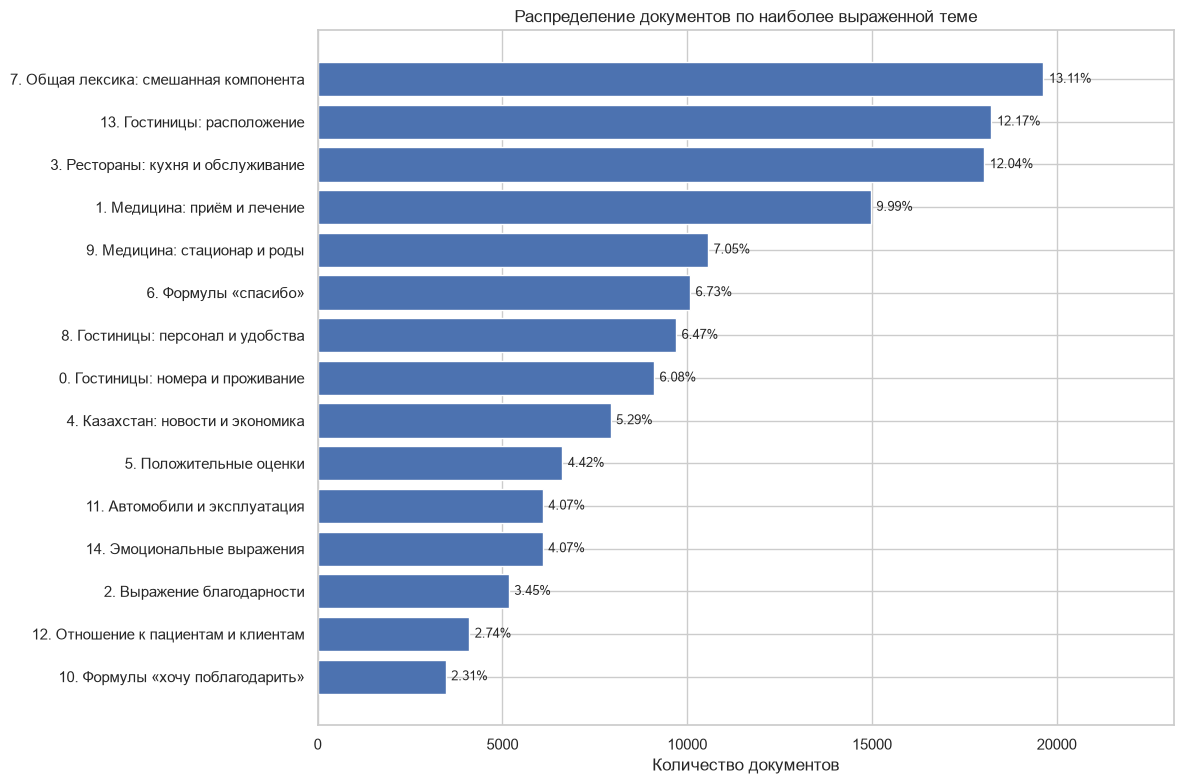

In [39]:
plot_data = topic_summary.sort_values("Количество документов")

fig, ax = plt.subplots(figsize=(12, 8))

labels = [
    f"{topic_id}. {name}"
    for topic_id, name in zip(plot_data["Тема"], plot_data["Название"])
]

bars = ax.barh(
    labels,
    plot_data["Количество документов"],
    color="#4C72B0",
)

shares = plot_data["Доля среди представленных документов, %"]

for bar, share in zip(bars, shares):
    ax.text(
        bar.get_width() + 150,
        bar.get_y() + bar.get_height() / 2,
        f"{share:.2f}%",
        va="center",
        fontsize=9,
    )

ax.set_title("Распределение документов по наиболее выраженной теме")
ax.set_xlabel("Количество документов")
ax.set_ylabel("")
ax.set_xlim(
    0,
    plot_data["Количество документов"].max() * 1.18,
)

plt.tight_layout()
plt.show()

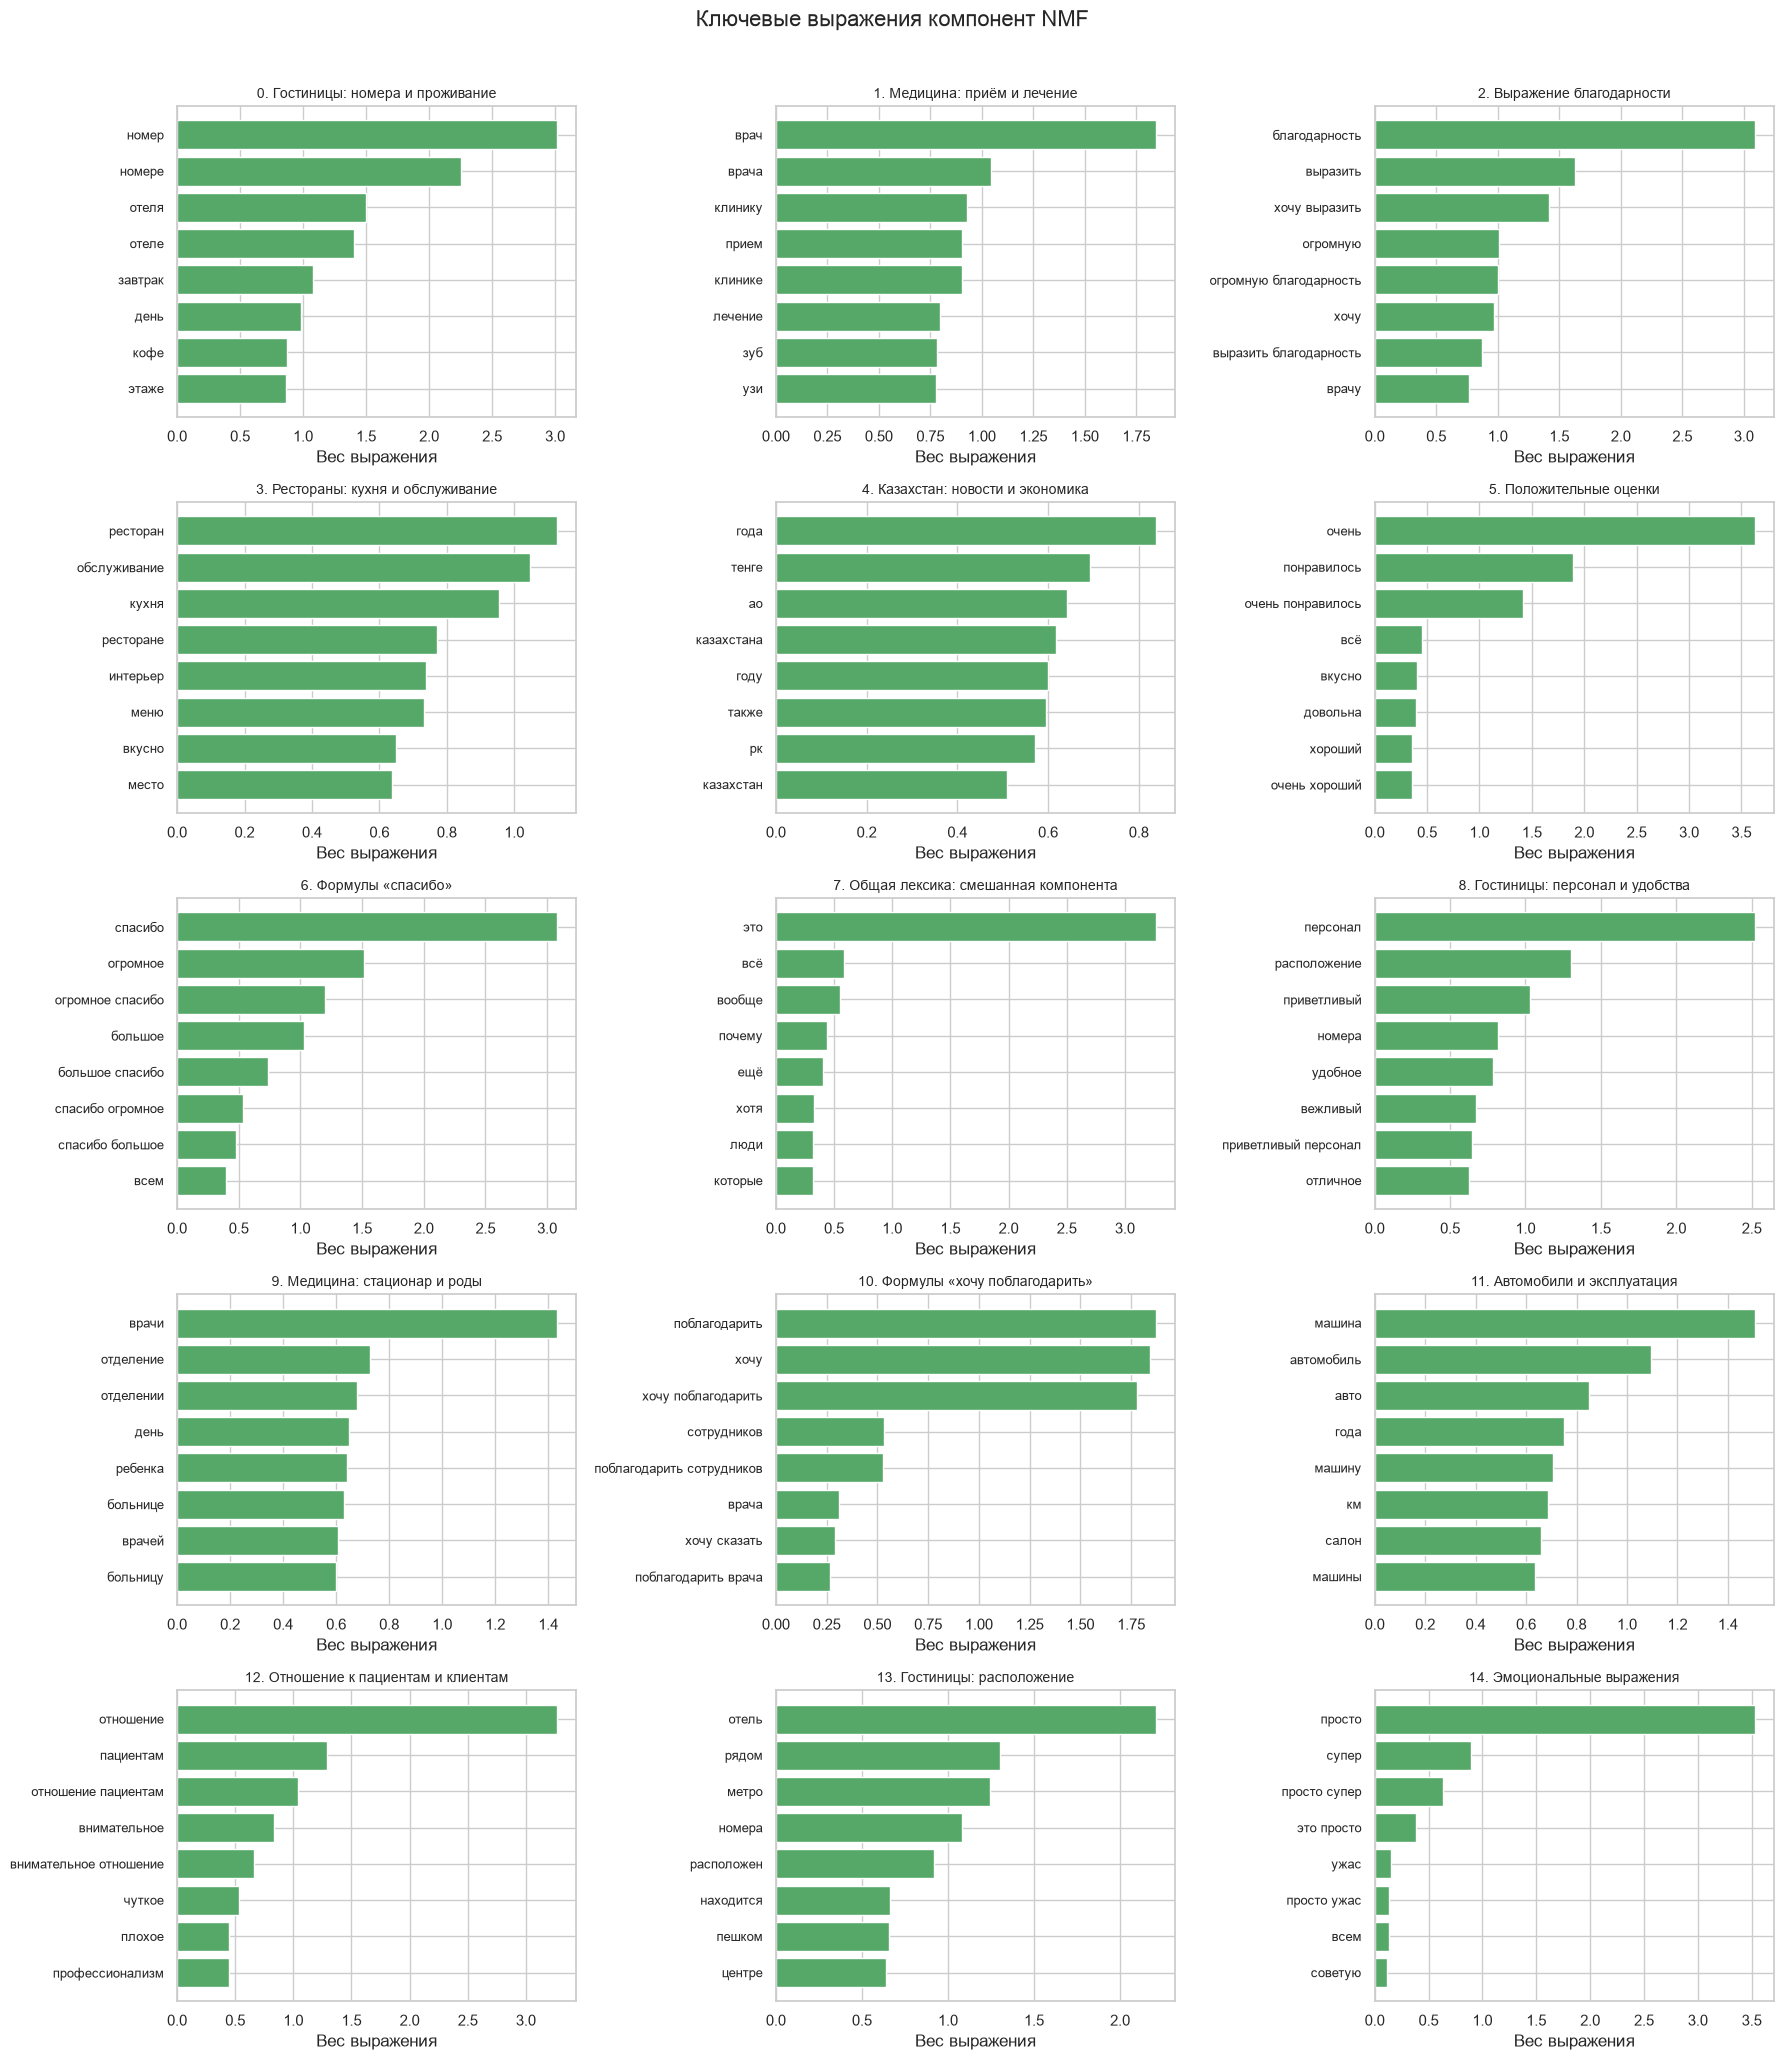

In [40]:
TOP_TERMS_TO_PLOT = 8

fig, axes = plt.subplots(
    nrows=5,
    ncols=3,
    figsize=(18, 21),
)

for topic_id, ax in enumerate(axes.ravel()):
    weights = nmf_model.components_[topic_id]

    # Выбираем самые весомые выражения.
    # Порядок нужен, чтобы самое весомое оказалось сверху.
    top_indices = weights.argsort()[-TOP_TERMS_TO_PLOT:]

    ax.barh(
        feature_names[top_indices],
        weights[top_indices],
        color="#55A868",
    )

    ax.set_title(
        f"{topic_id}. {TOPIC_NAMES[topic_id]}",
        fontsize=10,
    )
    ax.set_xlabel("Вес выражения")
    ax.tick_params(axis="y", labelsize=9)

fig.suptitle(
    "Ключевые выражения компонент NMF",
    fontsize=16,
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Что получилось с темами

По ключевым словам и просмотренным документам удалось выделить гостиницы, медицину, рестораны, автомобили и новости Казахстана

Если для каждого документа брать компоненту с самым большим весом, самые крупные группы получаются такими

| Основная компонента | Доля документов |
|---|---:|
| Общая лексика | 13,11% |
| Расположение гостиниц | 12,17% |
| Рестораны | 12,04% |
| Приём и лечение | 9,99% |

Здесь учитываются документы с ненулевыми признаками. У одного текста может быть несколько тем, но в этой таблице он попадает только в одну группу

Не все 15 компонент стали отдельными предметными темами. Модель выделила формулы благодарности и оценочные выражения, а гостиничные и медицинские темы частично пересекаются

Это результат первого эксперимента. Количество компонент не подбиралось, а качество проверялось по словам и ограниченному набору документов, поэтому говорить об оптимальном решении пока рано

### Что можно попробовать дальше

Эти варианты пока только предлагаю, без реализации

- Добавить лемматизацию, чтобы «врач», «врача» и «врачу» стали одной формой. Это может сделать словарь компактнее, но нужно проверить, станут ли темы понятнее
- Уточнить стоп-слова и попробовать убрать общие оценочные шаблоны. Здесь важно не удалить выражения, которые полезны для конкретной темы
- Сравнить несколько значений числа компонент по связности ключевых слов, различиям между темами и соответствию документов
- Попробовать BERTopic и проверить, поможет ли смысловая близость объединять синонимы и различать тексты с похожими словами, но разным смыслом
- Разбивать длинные обзоры на смысловые фрагменты. В одном документе может быть несколько сюжетов, но при сравнении придётся учитывать, что единицей анализа стал фрагмент
- Повторить обучение с другими случайными состояниями и на подвыборках, чтобы проверить устойчивость основных тем


## 4. Классификация тональности

### Сначала простой классификатор

Начну с TF-IDF и логистической регрессии. Она работает на CPU, подходит для разреженных признаков и даёт вероятности классов. Этот результат будет точкой сравнения для нейросети

Можно было взять наивный Байес, но он делает сильное предположение об условной независимости признаков. Ещё один вариант — линейный SVM, у которого вероятности потребовали бы дополнительной калибровки

Основной метрикой беру Macro-F1, чтобы качество каждого из трёх классов имело одинаковый вес при умеренном дисбалансе. Дополнительно посмотрю accuracy и показатели отдельных классов. Обучение минимизирует многоклассовую кросс-энтропию с L2-регуляризацией

Для этой задачи создаю отдельный TF-IDF. Стоп-слова не удаляю, чтобы сохранить отрицания. Словарь и веса IDF обучаются только на train, модели сравниваются на validation. Test пока не использую

В признаки войдут слова и пары слов, например «не понравилось». `min_df=3` убирает совсем редкие выражения, а `max_features=50 000` ограничивает словарь и затраты на вычисления. `C=1,0` беру как начальную силу регуляризации, отдельно её не подбирал. Веса классов пока не применяю. Предел 1 000 итераций оставляет запас для сходимости


In [41]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
)

y_train = train_data["sentiment"]
y_val = val_data["sentiment"]

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(
    np.zeros((len(train_data), 1)),
    y_train,
)

dummy_val_predictions = dummy_model.predict(
    np.zeros((len(val_data), 1))
)

dummy_accuracy = accuracy_score(y_val, dummy_val_predictions)
dummy_macro_f1 = f1_score(
    y_val,
    dummy_val_predictions,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0,
)

print(f"Dummy accuracy: {dummy_accuracy:.4f}")
print(f"Dummy Macro-F1: {dummy_macro_f1:.4f}")

Dummy accuracy: 0.4746
Dummy Macro-F1: 0.2146


In [42]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=3,
            max_df=0.98,
            max_features=50_000,
            sublinear_tf=True,
        ),
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            solver="lbfgs",
            max_iter=1000,
            class_weight=None,
        ),
    ),
])

start_time = perf_counter()

baseline_model.fit(train_data["text"], y_train)

baseline_training_seconds = perf_counter() - start_time

print(f"Время обучения: {baseline_training_seconds:.1f} секунд")
print(
    "Итераций классификатора:",
    baseline_model.named_steps["classifier"].n_iter_,
)

Время обучения: 97.9 секунд
Итераций классификатора: [134]


In [43]:
baseline_val_predictions = baseline_model.predict(val_data["text"])

baseline_accuracy = accuracy_score(y_val, baseline_val_predictions)
baseline_macro_f1 = f1_score(
    y_val,
    baseline_val_predictions,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0,
)

comparison = pd.DataFrame({
    "Модель": [
        "Всегда самый частый класс",
        "TF-IDF + LogisticRegression",
    ],
    "Validation accuracy": [
        dummy_accuracy,
        baseline_accuracy,
    ],
    "Validation Macro-F1": [
        dummy_macro_f1,
        baseline_macro_f1,
    ],
})

display(comparison.round(4))

print(classification_report(
    y_val,
    baseline_val_predictions,
    labels=[0, 1, 2],
    target_names=[LABEL_NAMES[label] for label in [0, 1, 2]],
    digits=4,
    zero_division=0,
))

,Модель,Validation accuracy,Validation Macro-F1
0,Всегда самый частый класс,0.4746,0.2146
1,TF-IDF + LogisticRegression,0.7766,0.7629


               precision    recall  f1-score   support

  Нейтральная     0.6599    0.6699    0.6649      6623
Положительная     0.8145    0.8255    0.8199     12581
Отрицательная     0.8194    0.7891    0.8040      7303

     accuracy                         0.7766     26507
    macro avg     0.7646    0.7615    0.7629     26507
 weighted avg     0.7772    0.7766    0.7768     26507



### Результат простого классификатора

TF-IDF + LogisticRegression обучился за 97,9 секунды вместе с построением признаков. Самому классификатору понадобилось 134 итерации

На validation получилась заметная разница с предсказанием самого частого класса

| Модель | Accuracy | Macro-F1 |
|---|---:|---:|
| Самый частый класс | 0,4746 | 0,2146 |
| TF-IDF + LogisticRegression | 0,7766 | 0,7629 |

Сложнее всего оказался нейтральный класс с F1 0,6649. У положительного F1 0,8199, у отрицательного — 0,8040

Посмотрю ошибки на validation, чтобы понять, что именно путает модель. Test на этом этапе не трогаю


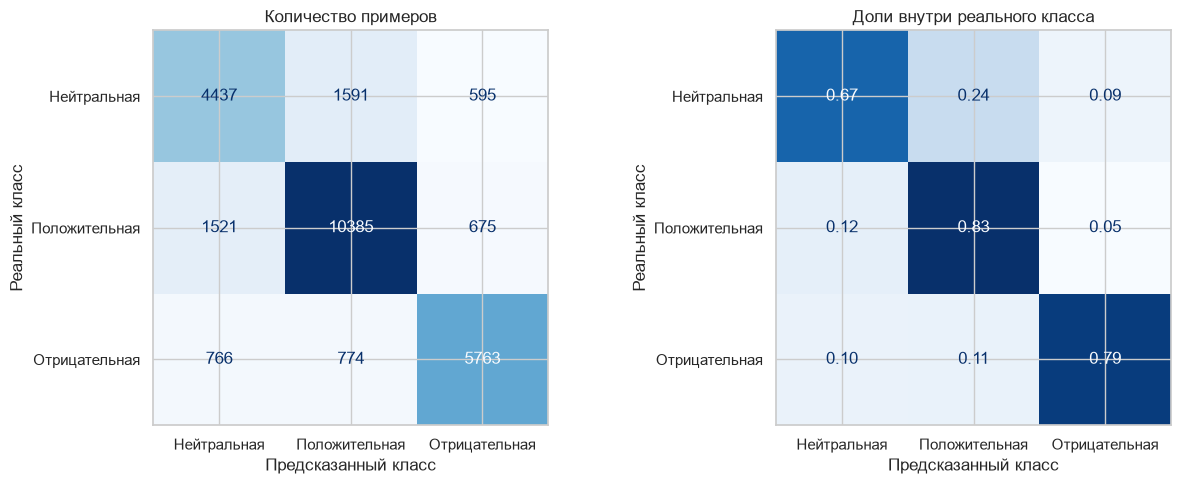

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, normalization, title in [
    (axes[0], None, "Количество примеров"),
    (axes[1], "true", "Доли внутри реального класса"),
]:
    matrix = confusion_matrix(
        y_val,
        baseline_val_predictions,
        labels=[0, 1, 2],
        normalize=normalization,
    )

    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Нейтральная", "Положительная", "Отрицательная"],
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d" if normalization is None else ".2f",
        colorbar=False,
    )

    ax.set_title(title)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Реальный класс")

plt.tight_layout()
plt.show()



In [45]:
validation_results = val_data.copy()
validation_results["prediction"] = baseline_val_predictions

validation_errors = validation_results.loc[
    validation_results["sentiment"] != validation_results["prediction"]
].copy()

for label in [0, 1, 2]:
    class_errors = validation_errors.loc[
        validation_errors["sentiment"] == label
    ]

    print("\n" + "=" * 70)
    print(f"ИСХОДНАЯ МЕТКА: {LABEL_NAMES[label]}")
    print(f"Ошибок: {len(class_errors)}")

    examples = class_errors.sample(
        n=min(3, len(class_errors)),
        random_state=RANDOM_STATE,
    )

    for index, row in examples.iterrows():
        print(f"\nИндекс validation: {index}")
        print("Предсказание:", LABEL_NAMES[row["prediction"]])
        print(row["text"][:1500])

        if len(row["text"]) > 1500:
            print("[Для показа оставлены первые 1500 символов]")


ИСХОДНАЯ МЕТКА: Нейтральная
Ошибок: 2186

Индекс validation: 8607
Предсказание: Отрицательная
Очень понравилось литовское пиво и национальная кухня .  А вот обслуживание ужасное .  Возможно , просто с официанткой не повезло .  В 21.00 играли музыканты .  

Индекс validation: 15840
Предсказание: Отрицательная
ХОРОШЕЕ БЫЛО МЕСТО !  А ТЕПЕРЬ ДРЯНЬ .. ОБСЛУЖИВАНИЕ УЖАСНОЕ , КУХНЯ ОЧЕНЬ СТРАННАЯ : И НЕ СКАЖЕШЬ ЧТО СОВСЕМ ПЛОХО , НО ВРОДЕ БЫ И БЛЮДО УДАЛОСЬ , ТАК ПРИНЕСУТ ЛЕДЯНОЕ .. А ПРИМЕШАТЬ В ГОТОВОЕ БЛЮДО СУХОЙ БАЗИЛИК ( ИЗ ПАКЕТА ) , ЧТОБЫ БЫЛО ОЩУЩЕНИЕ .  ЧТО ПЕРЕЖЕВЫВАЕШЬ СИЛОС , ЭТО ВАЩЕ КУЛИНАРНАЯ НАХОДКА !! (((  

Индекс validation: 24721
Предсказание: Положительная
Решила написать отзыв о своей машинке. 

ИСХОДНАЯ МЕТКА: Положительная
Ошибок: 2196

Индекс validation: 5625
Предсказание: Нейтральная
да ему не так просто как теневому олигарху бабло переводить в другие оффшоры  Не каждый бизнесмен - жулик  А сфигали он лично за них всех впрягается, делая такие заявления? Тем более п

In [46]:
import joblib

ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(exist_ok=True)

baseline_path = ARTIFACTS_DIR / "tfidf_logreg.joblib"

joblib.dump(baseline_model, baseline_path)

print("Модель сохранена:", baseline_path.resolve())

Модель сохранена: /Users/dimsalabimmm/programming/ml-test/artifacts/tfidf_logreg.joblib


### Что видно по ошибкам

Чаще всего путаются нейтральный и положительный классы. Нейтральный был предсказан как положительный в 1 591 случае, обратная ошибка встретилась 1 521 раз

В примерах есть смешанные оценки, малоинформативные тексты и ошибки модели в определении общего смысла. Встречаются и метки, которые выглядят сомнительно по содержанию отзыва

По этим примерам нельзя оценить, сколько ошибок разметки во всём датасете. Метки не меняю и не удаляю из validation тексты только потому, что модель с ними не согласилась


### Какую нейросеть беру

Для дообучения выбрал `cointegrated/rubert-tiny2`, компактную русскоязычную модель семейства BERT

Она требует меньше вычислений, чем более крупные BERT-модели, и позволяет учитывать контекст в отличие от TF-IDF с линейным классификатором

Добавлю классификационную часть для трёх классов и сравню результат с простым вариантом на validation

[Описание модели на Hugging Face](https://huggingface.co/cointegrated/rubert-tiny2)


In [47]:
import subprocess
import sys

subprocess.run(
    [
        "uv", "pip", "install",
        "--python", sys.executable,
        "torch",
        "transformers",
        "safetensors",
        "tqdm",
    ],
    check=True,
)

Resolved 34 packages in 2.10s
Prepared 21 packages in 16.77s
Installed 21 packages in 367ms
 + annotated-doc==0.0.5
 + filelock==4.2.0
 + fsspec==2026.9.0
 + hf-xet==1.7.0
 + httpcore2==2.13.1
 + httpx2==2.13.1
 + huggingface-hub==2.2.0
 + markdown-it-py==4.2.0
 + mdurl==0.1.2
 + mpmath==1.3.0
 + networkx==3.7
 + rich==15.0.0
 + safetensors==0.8.0
 + setuptools==84.0.0
 + shellingham==1.5.4
 + sympy==1.14.0
 + tokenizers==0.23.3
 + torch==2.14.1
 + transformers==5.19.0
 + truststore==0.10.5
 + typer==0.27.3


CompletedProcess(args=['uv', 'pip', 'install', '--python', '/Users/dimsalabimmm/programming/ml-test/.venv/bin/python', 'torch', 'transformers', 'safetensors', 'tqdm'], returncode=0)

In [48]:
import platform
import torch
import transformers

print("Архитектура:", platform.machine())
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PyTorch собран с MPS:", torch.backends.mps.is_built())
print("MPS доступен:", torch.backends.mps.is_available())

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Выбранное устройство:", device)

# Небольшая проверка вычислений.
x = torch.tensor([1.0, 2.0, 3.0], device=device)
result = (x * 2).cpu()

print("Результат проверки:", result)

/Users/dimsalabimmm/programming/ml-test/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Архитектура: arm64
PyTorch: 2.14.1
Transformers: 5.19.0
PyTorch собран с MPS: True
MPS доступен: True
Выбранное устройство: mps
Результат проверки: tensor([2., 4., 6.])


In [79]:
from transformers import AutoTokenizer

MODEL_ID = "cointegrated/rubert-tiny2"

# Фиксируем конкретную версию файлов модели.
MODEL_REVISION = "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
)

print("Модель:", MODEL_ID)
print("Версия файлов:", MODEL_REVISION)
print("Размер словаря:", len(tokenizer))

Модель: cointegrated/rubert-tiny2
Версия файлов: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
Размер словаря: 83828


In [50]:
from tqdm import tqdm

length_sample = train_data.sample(
    n=min(5000, len(train_data)),
    random_state=RANDOM_STATE,
)

sample_texts = length_sample["text"].tolist()
token_lengths = []

TOKENIZATION_BATCH_SIZE = 128

for start in tqdm(
    range(0, len(sample_texts), TOKENIZATION_BATCH_SIZE),
    desc="Подсчёт токенов",
):
    batch_texts = sample_texts[
        start:start + TOKENIZATION_BATCH_SIZE
    ]

    encoded = tokenizer(
        batch_texts,
        add_special_tokens=True,
        truncation=False,
        padding=False,
        return_length=True,
        return_attention_mask=False,
        return_token_type_ids=False,
        verbose=False,
    )

    token_lengths.extend(encoded["length"])

token_lengths = np.asarray(token_lengths)

display(
    pd.Series(token_lengths, name="Количество токенов")
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .round(1)
)

Подсчёт токенов: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 40/40 [00:00<00:00, 61.47it/s]


count    5000.0
mean      171.8
std       285.8
min         5.0
50%       105.0
90%       343.0
95%       478.2
99%      1081.0
max      6771.0
Name: Количество токенов, dtype: float64

In [51]:
length_options = []

for max_length in [128, 256, 512]:
    truncated_count = int((token_lengths > max_length).sum())

    length_options.append({
        "Предел, токенов": max_length,
        "Текстов с обрезкой": truncated_count,
        "Доля с обрезкой, %": round(
            truncated_count / len(token_lengths) * 100,
            2,
        ),
    })

length_options = pd.DataFrame(length_options)

display(length_options)

,"Предел, токенов",Текстов с обрезкой,"Доля с обрезкой, %"
0,128,2063,41.26
1,256,813,16.26
2,512,220,4.40


### Длина входа и пробный запуск

Проверил случайные 5 000 текстов из train. Медианная длина составила 105 токенов, 90-й процентиль — 343, а 95-й — около 478 токенов

Для первого обучения возьму предел 256 токенов. В этой подвыборке он обрезает часть текста у 16,26% документов

Начальный батч будет из 16 текстов. Перед полным обучением сделаю короткий запуск, чтобы проверить память и оценить время шага


In [53]:
from torch.utils.data import Dataset, DataLoader
from transformers import DataCollatorWithPadding

MAX_LENGTH = 256
TRAIN_BATCH_SIZE = 16
TRIAL_STEPS = 40

trial_data = train_data.sample(
    n=TRAIN_BATCH_SIZE * TRIAL_STEPS,
    random_state=RANDOM_STATE,
).reset_index(drop=True)

trial_encodings = tokenizer(
    trial_data["text"].tolist(),
    truncation=True,
    max_length=MAX_LENGTH,
    padding=False,
)


class EncodedTextDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {
            key: values[index]
            for key, values in self.encodings.items()
        }
        item["labels"] = int(self.labels[index])
        return item


trial_dataset = EncodedTextDataset(
    trial_encodings,
    trial_data["sentiment"],
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt",
)

trial_loader = DataLoader(
    trial_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=0,
)

In [54]:
from transformers import AutoModelForSequenceClassification

torch.manual_seed(RANDOM_STATE)

trial_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
    num_labels=3,
    id2label=LABEL_NAMES,
    label2id={
        name: label
        for label, name in LABEL_NAMES.items()
    },
    attn_implementation="eager",
)

trial_model = trial_model.to(device)

parameter_count = sum(
    parameter.numel()
    for parameter in trial_model.parameters()
)

print(f"Количество параметров: {parameter_count:,}")
print("Устройство:", next(trial_model.parameters()).device)

Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 55/55 [00:00<00:00, 7697.51it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

Количество параметров: 29,194,707
Устройство: mps:0


In [55]:
trial_optimizer = torch.optim.AdamW(
    trial_model.parameters(),
    lr=2e-5,
    weight_decay=0.01,
)

trial_model.train()

step_times = []
trial_losses = []

for step, batch in enumerate(
    tqdm(trial_loader, desc="Пробное обучение")
):
    if device.type == "mps":
        torch.mps.synchronize()

    step_start = perf_counter()

    batch = {
        key: value.to(device)
        for key, value in batch.items()
    }

    trial_optimizer.zero_grad(set_to_none=True)

    outputs = trial_model(**batch)
    loss = outputs.loss

    if not torch.isfinite(loss).item():
        raise RuntimeError("Получено нечисловое значение функции потерь.")

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        trial_model.parameters(),
        max_norm=1.0,
    )

    trial_optimizer.step()

    if device.type == "mps":
        torch.mps.synchronize()

    step_times.append(perf_counter() - step_start)
    trial_losses.append(loss.detach().cpu().item())

print("Пробных шагов:", len(step_times))

# Первые шаги могут включать первоначальную подготовку GPU.
measured_times = np.asarray(step_times[5:])

mean_step_seconds = measured_times.mean()
steps_per_epoch = (
    len(train_data) + TRAIN_BATCH_SIZE - 1
) // TRAIN_BATCH_SIZE

print(f"Среднее время шага после прогрева: {mean_step_seconds:.3f} с")
print(
    "Оценка вычислений на одну эпоху:",
    f"{mean_step_seconds * steps_per_epoch / 60:.1f} мин",
)
print("Первые 5 значений loss:", np.round(trial_losses[:5], 4))
print("Последние 5 значений loss:", np.round(trial_losses[-5:], 4))

Пробное обучение: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 40/40 [00:15<00:00,  2.60it/s]

Пробных шагов: 40
Среднее время шага после прогрева: 0.213 с
Оценка вычислений на одну эпоху: 33.3 мин
Первые 5 значений loss: [1.096  1.0989 1.1021 1.1176 1.0998]
Последние 5 значений loss: [1.1194 1.0432 1.0438 0.9972 1.0442]


### Настройки основного обучения

Дообучаю `cointegrated/rubert-tiny2` с классификатором трёх классов

| Параметр | Значение |
|---|---|
| Максимальная длина | 256 токенов |
| Обучающий батч | 16 текстов |
| Эпохи | 3 |
| Оптимизатор | AdamW |
| Начальная скорость обучения | 2e-5 |
| Weight decay | 0,01 |
| Прогрев | Первые 5% шагов |
| Ограничение нормы градиента | 1,0 |
| Функция потерь | Многоклассовая кросс-энтропия без весов классов |
| Выбор лучшей модели | Максимальный Macro-F1 на validation |

Скорость обучения небольшая, поскольку модель уже предобучена. В начале она постепенно растёт во время прогрева, затем линейно уменьшается. Батч проверен пробным запуском, а три эпохи задают бюджет первого эксперимента. Веса классов пока не добавляю, но качество буду смотреть отдельно по каждому классу

Пробный запуск дал около 0,213 секунды на шаг. Это примерно 33,3 минуты на эпоху без проверки validation, подготовки батчей и сохранения


In [57]:
import gc
import random

# Удаляем пробную модель, оптимизатор и последние результаты вычислений.
for variable_name in [
    "trial_optimizer",
    "trial_model",
    "outputs",
    "loss",
    "batch",
]:
    globals().pop(variable_name, None)

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

In [58]:
def encode_texts(texts, batch_size=512):
    encodings = {}
    texts = list(texts)

    for start in tqdm(
        range(0, len(texts), batch_size),
        desc="Токенизация",
    ):
        encoded_batch = tokenizer(
            texts[start:start + batch_size],
            truncation=True,
            max_length=MAX_LENGTH,
            padding=False,
        )

        for key, values in encoded_batch.items():
            encodings.setdefault(key, []).extend(values)

    return encodings


train_encodings = encode_texts(train_data["text"])
val_encodings = encode_texts(val_data["text"])

train_dataset = EncodedTextDataset(
    train_encodings,
    train_data["sentiment"],
)

val_dataset = EncodedTextDataset(
    val_encodings,
    val_data["sentiment"],
)

loader_generator = torch.Generator()
loader_generator.manual_seed(RANDOM_STATE)

train_loader = DataLoader(
    train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
    collate_fn=data_collator,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=0,
)

print("Шагов обучения на эпоху:", len(train_loader))
print("Батчей validation:", len(val_loader))

Токенизация: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 52/52 [00:02<00:00, 21.98it/s]

Шагов обучения на эпоху: 9388
Батчей validation: 829


In [59]:
from transformers import get_linear_schedule_with_warmup

EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
    num_labels=3,
    id2label=LABEL_NAMES,
    label2id={
        name: label
        for label, name in LABEL_NAMES.items()
    },
    attn_implementation="eager",
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * 0.05)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)

BEST_MODEL_DIR = ARTIFACTS_DIR / "rubert_tiny2_best"
LAST_MODEL_DIR = ARTIFACTS_DIR / "rubert_tiny2_last"

print("Всего шагов:", total_steps)
print("Шагов прогрева:", warmup_steps)

Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 55/55 [00:00<00:00, 5425.75it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

Всего шагов: 28164
Шагов прогрева: 1408


In [60]:
def evaluate_classifier(model, loader, device):
    model.eval()

    predictions = []
    true_labels = []
    total_loss = 0.0
    total_examples = 0

    with torch.inference_mode():
        for batch in tqdm(loader, desc="Validation", leave=False):
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(**batch)
            batch_size = batch["labels"].shape[0]

            total_loss += outputs.loss.item() * batch_size
            total_examples += batch_size

            predictions.extend(
                outputs.logits.argmax(dim=1).cpu().tolist()
            )
            true_labels.extend(batch["labels"].cpu().tolist())

    return {
        "val_loss": total_loss / total_examples,
        "val_accuracy": accuracy_score(true_labels, predictions),
        "val_macro_f1": f1_score(
            true_labels,
            predictions,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
    }

In [61]:
history = []
best_macro_f1 = -1.0

for epoch in range(1, EPOCHS + 1):
    epoch_start = perf_counter()
    model.train()

    total_train_loss = 0.0
    total_train_examples = 0

    progress = tqdm(
        train_loader,
        desc=f"Эпоха {epoch}/{EPOCHS}",
    )

    for step, batch in enumerate(progress, start=1):
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad(set_to_none=True)

        outputs = model(**batch)
        loss = outputs.loss

        if not torch.isfinite(loss).item():
            raise RuntimeError("Функция потерь стала NaN или бесконечностью.")

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
        )

        optimizer.step()
        scheduler.step()

        batch_size = batch["labels"].shape[0]
        total_train_loss += loss.detach().item() * batch_size
        total_train_examples += batch_size

        if step % 100 == 0:
            progress.set_postfix(
                loss=f"{total_train_loss / total_train_examples:.4f}"
            )

    metrics = evaluate_classifier(model, val_loader, device)

    improved = metrics["val_macro_f1"] > best_macro_f1

    if improved:
        best_macro_f1 = metrics["val_macro_f1"]
        model.save_pretrained(BEST_MODEL_DIR)
        tokenizer.save_pretrained(BEST_MODEL_DIR)

    # Последнее состояние сохраняется независимо от улучшения.
    model.save_pretrained(LAST_MODEL_DIR)
    tokenizer.save_pretrained(LAST_MODEL_DIR)

    epoch_result = {
        "epoch": epoch,
        "train_loss": total_train_loss / total_train_examples,
        **metrics,
        "epoch_minutes": (perf_counter() - epoch_start) / 60,
        "saved_as_best": improved,
    }

    history.append(epoch_result)

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        ARTIFACTS_DIR / "neural_training_history.csv",
        index=False,
    )

    display(history_df.round(4))

print("Обучение завершено.")
print(f"Лучший validation Macro-F1: {best_macro_f1:.4f}")
print("Лучшая модель:", BEST_MODEL_DIR.resolve())

Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 15.47it/s]


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,epoch_minutes,saved_as_best
0,1,0.5615,0.4558,0.7973,0.7814,30.5661,True


Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 14.11it/s]


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,epoch_minutes,saved_as_best
0,1,0.5615,0.4558,0.7973,0.7814,30.5661,True
1,2,0.4154,0.4411,0.8077,0.7916,29.9452,True


Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 16.13it/s]


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,epoch_minutes,saved_as_best
0,1,0.5615,0.4558,0.7973,0.7814,30.5661,True
1,2,0.4154,0.4411,0.8077,0.7916,29.9452,True
2,3,0.3640,0.4433,0.8131,0.8014,29.8657,True


Обучение завершено.
Лучший validation Macro-F1: 0.8014
Лучшая модель: /Users/dimsalabimmm/programming/ml-test/artifacts/rubert_tiny2_best


### Как прошло обучение

Три эпохи вместе с проверкой и сохранением заняли около 90,4 минуты. Macro-F1 на validation рос после каждой эпохи

```text
0,7814 → 0,7916 → 0,8014
```

Лучшей стала третья эпоха с accuracy 0,8131 и Macro-F1 0,8014. По Macro-F1 это на 3,85 процентного пункта выше TF-IDF + LogisticRegression

На третьей эпохе validation loss немного вырос, хотя основная метрика улучшилась. Для итоговой проверки беру сохранённые веса с лучшим validation Macro-F1

## 5. Окончательная оценка на test

Модель и настройки выбраны. Теперь проверю их на test, не используя этот результат для дальнейшего подбора параметров


In [62]:
# Освобождаем память обучающего состояния.
for variable_name in [
    "optimizer",
    "scheduler",
    "outputs",
    "loss",
    "batch",
    "model",
]:
    globals().pop(variable_name, None)

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

tokenizer = AutoTokenizer.from_pretrained(BEST_MODEL_DIR)

model = AutoModelForSequenceClassification.from_pretrained(
    BEST_MODEL_DIR,
    attn_implementation="eager",
).to(device)

model.eval()

print("Модель загружена из:", BEST_MODEL_DIR.resolve())
print("Устройство:", next(model.parameters()).device)

Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 57/57 [00:00<00:00, 5428.96it/s]


Модель загружена из: /Users/dimsalabimmm/programming/ml-test/artifacts/rubert_tiny2_best
Устройство: mps:0


In [63]:
test_encodings = encode_texts(test_data["text"])

test_dataset = EncodedTextDataset(
    test_encodings,
    test_data["sentiment"],
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt",
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=0,
)

print("Тестовых документов:", len(test_dataset))

Токенизация: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 40/40 [00:02<00:00, 19.82it/s]

Тестовых документов: 20074


In [64]:
def predict_classifier(model, loader, device):
    model.eval()
    predictions = []

    with torch.inference_mode():
        for batch in tqdm(loader, desc="Предсказания"):
            # Метки не передаём: для предсказания они не нужны.
            inputs = {
                key: value.to(device)
                for key, value in batch.items()
                if key != "labels"
            }

            logits = model(**inputs).logits

            predictions.extend(
                logits.argmax(dim=1).cpu().tolist()
            )

    return np.asarray(predictions)


neural_test_predictions = predict_classifier(
    model,
    test_loader,
    device,
)

print("Получено предсказаний:", len(neural_test_predictions))

Предсказания: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 628/628 [00:47<00:00, 13.32it/s]

Получено предсказаний: 20074


In [65]:
y_test = test_data["sentiment"].to_numpy()

baseline_test_predictions = baseline_model.predict(test_data["text"])

test_comparison = pd.DataFrame([
    {
        "Модель": name,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test Macro-F1": f1_score(
            y_test,
            predictions,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
    }
    for name, predictions in [
        ("TF-IDF + LogisticRegression", baseline_test_predictions),
        ("RuBERT-tiny2", neural_test_predictions),
    ]
])

display(test_comparison.round(4))

print("ОТЧЁТ ДЛЯ НЕЙРОСЕТИ НА TEST\n")

print(classification_report(
    y_test,
    neural_test_predictions,
    labels=[0, 1, 2],
    target_names=[LABEL_NAMES[label] for label in [0, 1, 2]],
    digits=4,
    zero_division=0,
))

test_predictions_table = pd.DataFrame({
    "test_row": np.arange(len(test_data)),
    "true_label": y_test,
    "baseline_prediction": baseline_test_predictions,
    "neural_prediction": neural_test_predictions,
})

test_predictions_table.to_csv(
    ARTIFACTS_DIR / "test_predictions.csv",
    index=False,
)

test_comparison.to_csv(
    ARTIFACTS_DIR / "test_metrics.csv",
    index=False,
)

,Модель,Test accuracy,Test Macro-F1
0,TF-IDF + LogisticRegression,0.7687,0.7566
1,RuBERT-tiny2,0.8080,0.7964


ОТЧЁТ ДЛЯ НЕЙРОСЕТИ НА TEST

               precision    recall  f1-score   support

  Нейтральная     0.7076    0.6876    0.6974      5099
Положительная     0.8426    0.8419    0.8423      9559
Отрицательная     0.8378    0.8613    0.8494      5416

     accuracy                         0.8080     20074
    macro avg     0.7960    0.7970    0.7964     20074
 weighted avg     0.8070    0.8080    0.8074     20074



### Результат на test

На тестовой выборке из 20 074 текстов получились такие результаты

| Модель | Accuracy | Macro-F1 |
|---|---:|---:|
| TF-IDF + LogisticRegression | 0,7687 | 0,7566 |
| RuBERT-tiny2 | 0,8080 | 0,7964 |

Нейросеть прибавила 3,98 процентного пункта по Macro-F1. Результат близок к validation, где было 0,8014 против 0,7964 на test

Нейтральный класс по-прежнему сложнее остальных. Его F1 составляет 0,6974, у положительного — 0,8423, у отрицательного — 0,8494

По результатам test настройки не меняю


In [67]:
cpu_name = subprocess.check_output(
    ["sysctl", "-n", "machdep.cpu.brand_string"],
    text=True,
).strip()

memory_bytes = int(
    subprocess.check_output(
        ["sysctl", "-n", "hw.memsize"],
        text=True,
    ).strip()
)

hardware_info = {
    "Процессор / чип": cpu_name,
    "Оперативная память, ГиБ": round(memory_bytes / 1024**3, 1),
    "macOS": platform.mac_ver()[0],
    "Архитектура": platform.machine(),
    "PyTorch": torch.__version__,
    "Потоков PyTorch на CPU": torch.get_num_threads(),
    "GPU backend": "Apple MPS",
}

display(pd.Series(hardware_info))

Процессор / чип            Apple M1 Pro
Оперативная память, ГиБ            16.0
macOS                            26.6.2
Архитектура                       arm64
PyTorch                          2.14.1
Потоков PyTorch на CPU                6
GPU backend                   Apple MPS
dtype: object

In [68]:
cpu_device = torch.device("cpu")

model = model.to(cpu_device)

cpu_test_predictions = predict_classifier(
    model,
    test_loader,
    cpu_device,
)

device_quality = pd.DataFrame([
    {
        "Устройство": name,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test Macro-F1": f1_score(
            y_test,
            predictions,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
    }
    for name, predictions in [
        ("CPU", cpu_test_predictions),
        ("GPU / MPS", neural_test_predictions),
    ]
])

display(device_quality.round(4))

prediction_agreement = (
    cpu_test_predictions == neural_test_predictions
).mean()

print(
    "Совпадение предсказаний CPU и GPU:",
    f"{prediction_agreement:.4%}",
)

device_quality.to_csv(
    ARTIFACTS_DIR / "device_quality.csv",
    index=False,
)

Предсказания: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 628/628 [02:32<00:00,  4.12it/s]


,Устройство,Test accuracy,Test Macro-F1
0,CPU,0.808,0.7964
1,GPU / MPS,0.808,0.7964


Совпадение предсказаний CPU и GPU: 100.0000%


## 6. Скорость работы на CPU и GPU

Для сравнения возьму одни и те же 512 случайных текстов из test. На обоих устройствах сохраняются предел 256 токенов, динамическое дополнение и float32

Проверю батчи 1 и 32. Сначала сделаю полный проход для прогрева, затем ещё три прохода для измерения. В таблицу попадут среднее время и стандартное отклонение

Время включает перенос подготовленных входов на устройство, работу модели, выбор класса и возврат ответа на CPU. Токенизацию, подготовку батчей и загрузку модели в него не включаю

Перед началом и после конца каждого измерения дожидаюсь завершения GPU-вычислений через синхронизацию


In [69]:
BENCHMARK_SIZE = 512
BENCHMARK_REPEATS = 3

rng = np.random.default_rng(RANDOM_STATE)

benchmark_indices = rng.choice(
    len(test_dataset),
    size=min(BENCHMARK_SIZE, len(test_dataset)),
    replace=False,
)

benchmark_batches = {}

for batch_size in [1, 32]:
    batches = []

    for start in range(0, len(benchmark_indices), batch_size):
        indices = benchmark_indices[start:start + batch_size]

        batch = data_collator([
            test_dataset[int(index)]
            for index in indices
        ])

        batches.append({
            key: value
            for key, value in batch.items()
            if key != "labels"
        })

    benchmark_batches[batch_size] = batches

print("Документов для измерения:", len(benchmark_indices))

Документов для измерения: 512


In [71]:
def synchronize_device(target_device):
    if target_device.type == "mps":
        torch.mps.synchronize()


def process_batch(model, batch, target_device):
    inputs = {
        key: value.to(target_device)
        for key, value in batch.items()
    }

    return model(**inputs).logits.argmax(dim=1).cpu()


def benchmark_classifier(model, batches, target_device):
    model.to(target_device)
    model.eval()

    durations = []

    with torch.inference_mode():
        # Прогрев не входит в результаты.
        # Полный проход для прогрева, без включения в результаты.
        for batch in batches:
            process_batch(model, batch, target_device)
        synchronize_device(target_device)

        for repeat in range(BENCHMARK_REPEATS):
            synchronize_device(target_device)
            start = perf_counter()

            for batch in batches:
                process_batch(model, batch, target_device)

            synchronize_device(target_device)
            elapsed = perf_counter() - start
            durations.append(elapsed)

            print(
                f"{target_device}: повтор {repeat + 1} — "
                f"{elapsed:.3f} с",
                flush=True,
            )

    return np.asarray(durations)


speed_rows = []
speed_measurements = []

for device_name, target_device in [
    ("CPU", torch.device("cpu")),
    ("GPU / MPS", torch.device("mps")),
]:
    for batch_size, batches in benchmark_batches.items():
        print(f"\n{device_name}, батч {batch_size}", flush=True)

        durations = benchmark_classifier(
            model,
            batches,
            target_device,
        )

        mean_seconds = durations.mean()
        document_count = len(benchmark_indices)

        speed_rows.append({
            "Устройство": device_name,
            "Батч": batch_size,
            "Документов": document_count,
            "Среднее время прохода, с": mean_seconds,
            "Стандартное отклонение, с": durations.std(ddof=1),
            "Среднее время на документ, мс": (
                mean_seconds / document_count * 1000
            ),
            "Документов/с": document_count / mean_seconds,
        })

        for repeat, seconds in enumerate(durations, start=1):
            speed_measurements.append({
                "Устройство": device_name,
                "Батч": batch_size,
                "Повтор": repeat,
                "Время, с": seconds,
            })

speed_results = pd.DataFrame(speed_rows)

display(speed_results.round(3))

speed_results.to_csv(
    ARTIFACTS_DIR / "inference_speed.csv",
    index=False,
)

pd.DataFrame(speed_measurements).to_csv(
    ARTIFACTS_DIR / "inference_speed_repeats.csv",
    index=False,
)

# Возвращаем модель на выбранное ранее устройство.
model.to(device);


CPU, батч 1
cpu: повтор 1 — 5.560 с
cpu: повтор 2 — 5.034 с
cpu: повтор 3 — 5.272 с

CPU, батч 32
cpu: повтор 1 — 3.216 с
cpu: повтор 2 — 4.356 с
cpu: повтор 3 — 3.685 с

GPU / MPS, батч 1
mps: повтор 1 — 7.643 с
mps: повтор 2 — 9.223 с
mps: повтор 3 — 8.035 с

GPU / MPS, батч 32
mps: повтор 1 — 1.034 с
mps: повтор 2 — 1.024 с
mps: повтор 3 — 1.070 с


,Устройство,Батч,Документов,"Среднее время прохода, с","Стандартное отклонение, с","Среднее время на документ, мс",Документов/с
0,CPU,1,512,5.289,0.263,10.330,96.808
1,CPU,32,512,3.752,0.573,7.328,136.455
2,GPU / MPS,1,512,8.300,0.822,16.211,61.685
3,GPU / MPS,32,512,1.043,0.024,2.037,490.900


### Что получилось по скорости

Измерения сделаны на Apple M1 Pro с 16 ГиБ объединённой памяти, macOS 26.6.2 и PyTorch 2.14.1. На CPU использовалось 6 потоков, на GPU — Apple MPS

На всей тестовой выборке предсказания CPU и GPU совпали на 100%. У обоих устройств accuracy 0,8080 и Macro-F1 0,7964

| Устройство | Батч 1, документов/с | Батч 32, документов/с |
|---|---:|---:|
| CPU | 96,8 | 136,5 |
| GPU | 61,7 | 490,9 |

При батче 32 GPU оказался примерно в 3,6 раза быстрее. При обработке по одному тексту лучше CPU, он быстрее примерно в 1,6 раза

Для этой модели на моём оборудовании CPU удобнее для одиночных текстов, а GPU — для пакетной обработки. Переносить эти цифры на другие устройства без измерений нельзя

Токенизация и загрузка модели здесь не учитываются. Время на документ при батче 32 — это время обработки группы, разделённое на количество текстов, а не задержка отдельного запроса


## 7. Что можно улучшить в классификаторе

### Качество

В первую очередь стоит проверить разметку на случайной выборке и сравнить правила разных источников. Сомнительные примеры уже встретились, но их общая доля пока неизвестна

Для длинных текстов можно сравнить пределы 256 и 512 токенов на validation или обрабатывать несколько фрагментов с объединением ответов. Это уменьшит потерю текста при обрезке, но добавит вычислений

Ещё можно подобрать скорость обучения, регуляризацию и число эпох, проверить веса классов. Сравнивать нужно Macro-F1 и показатели каждого класса, улучшение заранее не гарантировано

При наличии ресурсов стоит попробовать более крупную русскоязычную модель и сравнить не только качество, но и память со скоростью

Отдельный вопрос — близкие дубликаты и различия источников. Сейчас исключены только точные совпадения. Если доступны идентификаторы источников и объектов, можно сделать групповое разделение и проверить перенос на новые источники

### Скорость

- Подобрать размер батча под устройство, доступную память и допустимое время ожидания
- Собирать вместе тексты близкой длины, чтобы тратить меньше вычислений на заполнители
- Измерить токенизацию и полный путь от текста до ответа, а для повторяющихся запросов рассмотреть кэширование
- Проверить квантование, другие способы исполнения или уменьшенную точность на поддерживаемом оборудовании. Затем сравнить качество, скорость и совместимость операций

Это предложения для дальнейших экспериментов, здесь они не реализованы. Факультативную оптимизацию классификатора не выполнял


## 8. Итоги

В работе выполнены обе обязательные части задания

Сначала проверил данные и нашёл повторы, общие тексты в исходных файлах, противоречивые метки и признаки ошибок разметки. После очистки подготовил train, validation и test без точных пересечений. Близкие дубликаты отдельно не проверялись

Для поиска тем использовал TF-IDF + NMF. Получились и предметные темы, и речевые шаблоны. Результаты показаны на графиках, пересекающиеся и неоднозначные компоненты описаны вместе с вариантами улучшения

Для тональности обучил TF-IDF + LogisticRegression и RuBERT-tiny2. Лучшую эпоху нейросети выбрал по Macro-F1 на validation. На test она получила accuracy 0,8080 и Macro-F1 0,7964, обойдя линейный классификатор на 3,98 процентного пункта по Macro-F1. Самым сложным остался нейтральный класс

Также сравнил качество и скорость нейросети на CPU и GPU. Предсказания совпали, а преимущество по скорости зависело от размера батча

Основные ограничения — шумная разметка, отсутствие проверки близких дубликатов, обрезка длинных текстов и небольшой подбор параметров. По test модель не настраивалась. При этом сам test очищен от конфликтных текстов с учётом обоих исходных файлов, поэтому метрики относятся к этой выборке, а не ко всему исходному корпусу без фильтрации

Варианты улучшения качества и скорости перечислены без реализации. Необязательную оптимизацию не выполнял


In [77]:
freeze_result = subprocess.run(
    [
        "uv", "--color", "never",
        "pip", "freeze",
        "--python", sys.executable,
    ],
    check=True,
    capture_output=True,
    text=True,
)

requirements_text = freeze_result.stdout

assert "\x1b" not in requirements_text, (
    "В выводе остались управляющие символы."
)

requirements_path = Path("requirements.txt")
requirements_path.write_text(
    requirements_text,
    encoding="utf-8",
)

print("Список библиотек сохранён")

Список библиотек сохранён
